# Notebook 03 : expériences (tournois multi-graines, agents LLM)

**Projet 6, groupe 6.** Deux volets. (1) Les stratégies classiques : classement selon le bruit $\varepsilon$ et dynamique du réplicateur, sur **30 graines** avec 10 répétitions par paire, pour mesurer ce que la graine change. (2) Les agents LLM (Ollama) : au moins 10 parties de 10 manches par configuration (horizon annoncé ou non $\times$ deux modèles), contre TFT. Toutes les valeurs ci-dessous sont celles de l'exécution du notebook. Les fichiers de parties LLM sont ceux produits par `scripts/run_llm_games.py`, avec les vrais modèles ; **aucune sortie du faux modèle « scripté » n'intervient dans ce notebook**.

In [1]:
import sys, os, glob, json
sys.path.insert(0, "../src")
import numpy as np, matplotlib.pyplot as plt
from jeux import STRATEGIES, STRATEGIES_ETENDUES
from experiences import (classement_multi_graines, replicateur_multi_graines, charger_parties, coop_par_manche,
                         resume_config, comparer_horizons, theorie_induction)
os.makedirs("../docs/figures", exist_ok=True)
GRAINES = range(30); REPS = 10; MANCHES = 200
print("protocole classique : graines 0 à", max(GRAINES), "| répétitions par paire :", REPS, "| manches :", MANCHES)

protocole classique : graines 0 à 29 | répétitions par paire : 10 | manches : 200


## 1. Classement selon le bruit, sur 30 graines

Score moyen par manche et son intervalle de confiance à 95 % **entre graines**, rang moyen, et fraction de graines où la stratégie arrive première.

In [2]:
classements = {}
for eps in (0.0, 0.01, 0.05):
    classements[eps] = classement_multi_graines(bruit=eps, graines=GRAINES, manches=MANCHES, repetitions=REPS)
    print(f"\nepsilon = {eps}")
    print(f"{'stratégie':>11} {'score moyen':>12} {'± IC95':>8} {'rang moyen':>11} {'1re (graines)':>14}")
    for n, v in sorted(classements[eps].items(), key=lambda t: -t[1]["score"][0]):
        print(f"{n:>11} {v['score'][0]:12.3f} {v['score'][1]:8.3f} {v['rang_moyen']:11.2f} {v['premier']:14.2f}")


epsilon = 0.0
  stratégie  score moyen   ± IC95  rang moyen  1re (graines)
  rancunier        2.664    0.003        1.00           1.00
        TFT        2.540    0.001        2.00           0.00
     Pavlov        2.457    0.003        3.00           0.00
 toujours_D        2.342    0.002        4.00           0.00
 toujours_C        2.250    0.001        5.00           0.00
  aleatoire        1.969    0.003        6.00           0.00



epsilon = 0.01
  stratégie  score moyen   ± IC95  rang moyen  1re (graines)
  rancunier        2.357    0.015        1.43           0.57
 toujours_D        2.348    0.003        1.57           0.43
     Pavlov        2.193    0.017        3.07           0.00
        TFT        2.107    0.012        3.93           0.00
  aleatoire        1.972    0.003        5.00           0.00
 toujours_C        1.753    0.021        6.00           0.00



epsilon = 0.05
  stratégie  score moyen   ± IC95  rang moyen  1re (graines)
 toujours_D        2.369    0.003        1.27           0.73
  rancunier        2.359    0.006        1.73           0.27
     Pavlov        2.101    0.005        3.00           0.00
        TFT        2.022    0.006        4.10           0.00
  aleatoire        1.994    0.003        4.90           0.00
 toujours_C        1.602    0.008        6.00           0.00


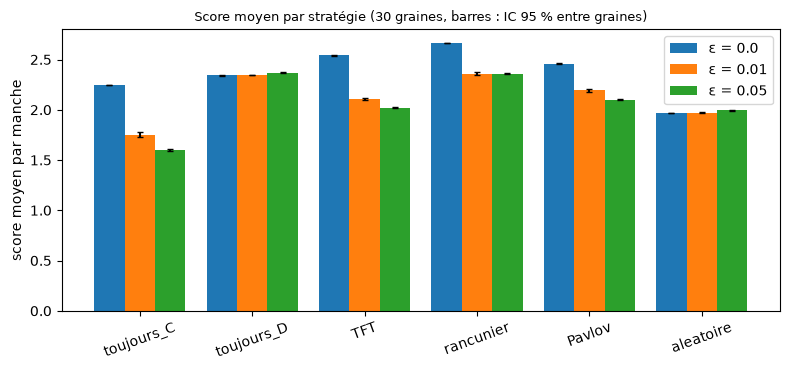

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8)); noms = list(STRATEGIES); x = np.arange(len(noms)); larg = 0.27
for k, eps in enumerate((0.0, 0.01, 0.05)):
    ax.bar(x + (k - 1) * larg, [classements[eps][n]["score"][0] for n in noms], larg,
           yerr=[classements[eps][n]["score"][1] for n in noms], capsize=2, label=f"ε = {eps}")
ax.set_xticks(x); ax.set_xticklabels(noms, rotation=20); ax.set_ylabel("score moyen par manche"); ax.legend()
ax.set_title("Score moyen par stratégie (30 graines, barres : IC 95 % entre graines)", fontsize=9)
plt.tight_layout(); plt.savefig("../docs/figures/fig_classement_bruit.png", dpi=150); plt.show()

## 2. TFT résiste-t-il au bruit ? Et le TFT généreux ?

On ajoute TFT généreux (pardon avec la probabilité 1/3) aux six stratégies.

In [4]:
for eps in (0.0, 0.05):
    r = classement_multi_graines(STRATEGIES_ETENDUES, bruit=eps, graines=GRAINES, manches=MANCHES, repetitions=REPS)
    print(f"epsilon = {eps}: " + " > ".join(f"{n} {v['score'][0]:.3f}" for n, v in sorted(r.items(), key=lambda t: -t[1]['score'][0])))
    print("   rang moyen de TFT :", round(r['TFT']['rang_moyen'], 2), "| de TFT_genereux :", round(r['TFT_genereux']['rang_moyen'], 2))

epsilon = 0.0: rancunier 2.712 > TFT 2.606 > Pavlov 2.535 > TFT_genereux 2.523 > toujours_C 2.357 > toujours_D 2.341 > aleatoire 2.092
   rang moyen de TFT : 2.0 | de TFT_genereux : 3.9


epsilon = 0.05: toujours_D 2.383 > rancunier 2.377 > Pavlov 2.199 > TFT 2.147 > aleatoire 2.108 > TFT_genereux 2.096 > toujours_C 1.782
   rang moyen de TFT : 4.03 | de TFT_genereux : 5.8


## 3. Dynamique du réplicateur depuis des parts égales, sur 30 graines

Pour chaque graine, parts finales à la génération 200 ; moyenne, écart-type entre graines, et fraction de graines où la stratégie domine la population.

In [5]:
for eps in (0.0, 0.01, 0.05):
    r = replicateur_multi_graines(bruit=eps, graines=GRAINES, manches=MANCHES, repetitions=REPS, generations=200)
    print(f"\nepsilon = {eps}")
    for n, v in sorted(r.items(), key=lambda t: -t[1]["part_moyenne"]):
        print(f"{n:>11} part moyenne {v['part_moyenne']:.3f} ± {v['part_ecart_type']:.3f} | dominante dans {v['domine']:.0%} des graines")


epsilon = 0.0
  rancunier part moyenne 0.344 ± 0.003 | dominante dans 100% des graines
        TFT part moyenne 0.282 ± 0.002 | dominante dans 0% des graines
     Pavlov part moyenne 0.227 ± 0.003 | dominante dans 0% des graines
 toujours_C part moyenne 0.146 ± 0.001 | dominante dans 0% des graines
 toujours_D part moyenne 0.000 ± 0.000 | dominante dans 0% des graines
  aleatoire part moyenne 0.000 ± 0.000 | dominante dans 0% des graines



epsilon = 0.01
  rancunier part moyenne 0.566 ± 0.454 | dominante dans 60% des graines
     Pavlov part moyenne 0.377 ± 0.453 | dominante dans 37% des graines
        TFT part moyenne 0.043 ± 0.178 | dominante dans 3% des graines
 toujours_C part moyenne 0.014 ± 0.055 | dominante dans 0% des graines
 toujours_D part moyenne 0.000 ± 0.001 | dominante dans 0% des graines
  aleatoire part moyenne 0.000 ± 0.000 | dominante dans 0% des graines



epsilon = 0.05
     Pavlov part moyenne 0.999 ± 0.001 | dominante dans 100% des graines
  rancunier part moyenne 0.001 ± 0.001 | dominante dans 0% des graines
 toujours_D part moyenne 0.000 ± 0.000 | dominante dans 0% des graines
        TFT part moyenne 0.000 ± 0.000 | dominante dans 0% des graines
  aleatoire part moyenne 0.000 ± 0.000 | dominante dans 0% des graines
 toujours_C part moyenne 0.000 ± 0.000 | dominante dans 0% des graines


## 4. Agents LLM contre TFT

Fichiers lus : `resultats/llm_<modèle>_<horizon>_TFT.jsonl`. Pour chaque configuration : fréquence de coopération (intervalle bootstrap à 95 % **sur les parties**, car les coups d'une partie ne sont pas indépendants), nombre de trajectoires distinctes, coopération à la première et à la dernière manche, score moyen par manche, et **nombre de réponses sans « CHOIX : »** (comptées à part, remplacées par le coup par défaut « coopérer »).

In [6]:
fichiers = sorted(glob.glob("../resultats/llm_*_TFT.jsonl"))
configs = {}
for f in fichiers:
    meta, parties = charger_parties(f)
    configs[(meta["modele"], meta["horizon_annonce"])] = (meta, parties)
    r = resume_config(meta, parties)
    print(f"{meta['modele']:>9} | horizon annoncé : {str(meta['horizon_annonce']):5} | parties : {r['parties']} x {r['manches']} manches | "
          f"coopération {r['coop']:.1%} (IC95 {r['coop_ic95'][0]:.1%} à {r['coop_ic95'][1]:.1%}) | trajectoires distinctes {r['trajectoires_distinctes']}/{r['parties']} | 1re manche {r['coop_premiere_manche']:.0%}, "
          f"dernière {r['coop_derniere_manche']:.0%} | score {r['score_moyen']:.2f} ± {r['score_ic95']:.2f} | hors format {r['defauts']}/{r['appels']}")
    print(f"           version du modèle : empreinte {str(meta['digest'])[:12]}, serveur Ollama {meta['serveur_ollama']}, température {meta['temperature']}")
if not fichiers:
    print("aucun fichier de parties LLM trouvé : lancer scripts/run_llm_games.py")

 llama3.1 | horizon annoncé : True  | parties : 10 x 10 manches | coopération 63.0% (IC95 36.0% à 90.0%) | trajectoires distinctes 3/10 | 1re manche 70%, dernière 70% | score 2.45 ± 0.45 | hors format 0/100
           version du modèle : empreinte 46e0c10c039e, serveur Ollama 0.40.16, température 0.7
 llama3.1 | horizon annoncé : False | parties : 10 x 10 manches | coopération 31.0% (IC95 16.0% à 44.0%) | trajectoires distinctes 3/10 | 1re manche 70%, dernière 60% | score 1.85 ± 0.27 | hors format 0/100
           version du modèle : empreinte 46e0c10c039e, serveur Ollama 0.40.16, température 0.7
  qwen2.5 | horizon annoncé : True  | parties : 10 x 10 manches | coopération 68.0% (IC95 64.0% à 72.0%) | trajectoires distinctes 3/10 | 1re manche 100%, dernière 10% | score 2.82 ± 0.06 | hors format 0/100
           version du modèle : empreinte 845dbda0ea48, serveur Ollama 0.40.16, température 0.7
  qwen2.5 | horizon annoncé : False | parties : 10 x 10 manches | coopération 83.0% (IC95 80.

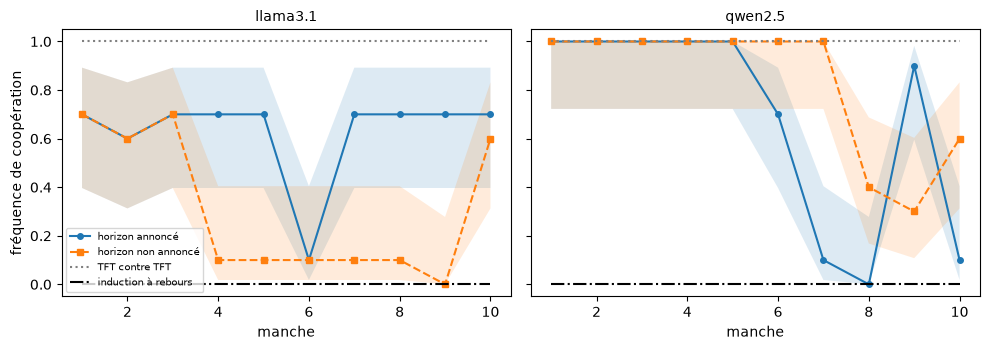

In [7]:
if configs:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, modele in zip(axes, sorted({k[0] for k in configs})):
        for annonce, style in ((True, "-o"), (False, "--s")):
            if (modele, annonce) in configs:
                taux, bas, haut = coop_par_manche(configs[(modele, annonce)][1])
                m = np.arange(1, len(taux) + 1)
                ax.plot(m, taux, style, label=f"horizon {'annoncé' if annonce else 'non annoncé'}", ms=4)
                ax.fill_between(m, bas, haut, alpha=0.15)
        ax.plot(np.arange(1, 11), np.ones(10), ":", color="grey", label="TFT contre TFT")
        ax.plot(np.arange(1, 11), theorie_induction(10), "-.", color="black", label="induction à rebours")
        ax.set_title(modele, fontsize=10); ax.set_xlabel("manche"); ax.set_ylim(-0.05, 1.05)
    axes[0].set_ylabel("fréquence de coopération"); axes[0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig("../docs/figures/fig_coop_llm.png", dpi=150); plt.show()

### Effet de l'horizon annoncé

Comparaison de la coopération **par partie** (10 parties par groupe, test de Mann-Whitney bilatéral). Avec cet effectif, la puissance est faible : un résultat non significatif ne prouve pas l'absence d'effet.

In [8]:
for modele in sorted({k[0] for k in configs}):
    if (modele, True) in configs and (modele, False) in configs:
        r = comparer_horizons(configs[(modele, True)][1], configs[(modele, False)][1])
        print(f"{modele:>9} : coopération par partie {r['coop_annonce']:.2f} (annoncé) contre {r['coop_non_annonce']:.2f} (non annoncé) ; "
              f"Mann-Whitney U = {r['U']:.1f}, p = {r['p']:.3f} (n = {r['n_annonce']} et {r['n_non']})")

 llama3.1 : coopération par partie 0.63 (annoncé) contre 0.31 (non annoncé) ; Mann-Whitney U = 74.5, p = 0.057 (n = 10 et 10)
  qwen2.5 : coopération par partie 0.68 (annoncé) contre 0.83 (non annoncé) ; Mann-Whitney U = 3.5, p = 0.000 (n = 10 et 10)


### Réponses brutes relevées

Les fichiers complets de réponses brutes sont restés sur la machine qui a joué les parties ; l'en-tête de chaque fichier conserve la première et la dernière réponse de la partie 1, et le texte complet est disponible quand le fichier contient `reponses` (parties rejouées en local).

In [9]:
for (modele, annonce), (meta, parties) in sorted(configs.items()):
    brut = parties[0]["reponses"]
    r1, r10 = (brut[0], brut[-1]) if brut else (meta.get("reponse_manche1_partie1"), meta.get("reponse_manche10_partie1"))
    print(f"{modele} / annoncé={annonce} : manche 1 -> {r1!r} ; manche 10 -> {r10!r} ; matériel : {meta.get('materiel')}")

llama3.1 / annoncé=False : manche 1 -> 'CHOIX : COOPERER' ; manche 10 -> 'CHOIX : COOPERER' ; matériel : Colab_T4_GPU (Tesla T4, pilote 580.82.07)
llama3.1 / annoncé=True : manche 1 -> 'CHOIX : COOPERER' ; manche 10 -> 'CHOIX : COOPERER' ; matériel : Colab_T4_GPU (Tesla T4, pilote 580.82.07)
qwen2.5 / annoncé=False : manche 1 -> 'CHOIX : COOPERER' ; manche 10 -> 'CHOIX : COOPERER' ; matériel : Colab_T4_GPU (Tesla T4, pilote 580.82.07)
qwen2.5 / annoncé=True : manche 1 -> 'CHOIX : COOPERER' ; manche 10 -> 'CHOIX : TRAHIR' ; matériel : Colab_T4_GPU (Tesla T4, pilote 580.82.07)


## 5. Essais de l'agent LangChain avec un vrai modèle

Fichiers `resultats/agent_<modèle>.jsonl` : chaque question est posée 3 fois ; le contrôle automatique vérifie l'outil appelé et ses arguments (Q5 est hors sujet : aucun outil attendu).

In [10]:
from controles_agent import controle
for f in sorted(glob.glob("../resultats/agent_*.jsonl")):
    lignes = [l for l in map(json.loads, open(f, encoding="utf-8")) if not l.get("meta")]
    def conforme(l):                       # contrôle tolérant recalculé à partir des arguments enregistrés quand ils existent
        if "appels_outils" in l:
            return controle(l["question_id"], [(n, a) for n, a in l["appels_outils"]])
        return l["controle_ok"] if "outils_appeles" in l else None      # None : exception, essai non exploitable
    res = [conforme(l) for l in lignes]
    exploitables = [r for r in res if r is not None]
    print(f"\n{os.path.basename(f)} : {sum(exploitables)}/{len(exploitables)} essais exploitables conformes ; {res.count(None)} essai(s) non exploitable(s) (exception)")
    for q in sorted({l["question_id"] for l in lignes}):
        ids = [i for i, l in enumerate(lignes) if l["question_id"] == q]
        print(f"   {q} : conformes {sum(bool(res[i]) for i in ids)}/{len(ids)} ; non exploitables {sum(res[i] is None for i in ids)} ; durée moyenne {np.mean([lignes[i]['duree_s'] for i in ids]):.0f} s")


agent_llama3.1_colab.jsonl : 15/15 essais exploitables conformes ; 0 essai(s) non exploitable(s) (exception)
   Q1 : conformes 3/3 ; non exploitables 0 ; durée moyenne 4 s
   Q2 : conformes 3/3 ; non exploitables 0 ; durée moyenne 4 s
   Q3 : conformes 3/3 ; non exploitables 0 ; durée moyenne 10 s
   Q4 : conformes 3/3 ; non exploitables 0 ; durée moyenne 13 s
   Q5 : conformes 3/3 ; non exploitables 0 ; durée moyenne 2 s

agent_llama3.1_local_cpu.jsonl : 12/12 essais exploitables conformes ; 3 essai(s) non exploitable(s) (exception)
   Q1 : conformes 3/3 ; non exploitables 0 ; durée moyenne 97 s
   Q2 : conformes 3/3 ; non exploitables 0 ; durée moyenne 110 s
   Q3 : conformes 3/3 ; non exploitables 0 ; durée moyenne 172 s
   Q4 : conformes 0/3 ; non exploitables 3 ; durée moyenne 175 s
   Q5 : conformes 3/3 ; non exploitables 0 ; durée moyenne 19 s

agent_qwen2.5_colab.jsonl : 15/15 essais exploitables conformes ; 0 essai(s) non exploitable(s) (exception)
   Q1 : conformes 3/3 ; non